In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv(r'C:\Users\User\Desktop\Patient Profile & Diagnosis Trends\patient_visits.csv')

In [5]:
df['date_of_birth']=pd.to_datetime(df['date_of_birth'])

In [6]:
df['AgeP']=(df['date_of_birth'].dt.year-2026)*-1

In [7]:
df

,visit_id,patient_id,visit_date,date_of_birth,patient_age,patient_sex,icd_code,cpt_code,Age,AgeP
0,V000001,PT00001,3/15/2022,1956-07-22,66,Male,I10,12345,70.350685,70
1,V000002,PT00002,4/22/2022,1982-11-05,39,Female,E11.9,23456,44.043836,44
2,V000003,PT00003,5/10/2022,1978-02-14,44,Male,J45.909,34567,48.769863,48
3,V000004,PT00004,1/18/2023,2004-09-02,57,Female,N39.0,45678,22.202740,22
4,V000005,PT00005,7/30/2023,1948-03-19,75,Male,I25.110,56789,78.698630,78
...,...,...,...,...,...,...,...,...,...,...
195,V000018,PT00018,9/9/2024,1977-12-03,46,Female,I10,98011,48.969863,49
196,V000019,PT00019,5/25/2022,1995-07-21,28,Male,J02.9,21004,31.328767,31
197,V000020,PT00020,7/12/2023,2004-11-02,38,Female,E78.0,26009,22.035616,22
198,V000021,PT00021,4/3/2024,1969-04-08,55,Male,I10,52018,57.630137,57


In [8]:
pd.set_option('display.max.rows',205)
pd.set_option('display.max.columns',12)

In [9]:
df

,visit_id,patient_id,visit_date,date_of_birth,patient_age,patient_sex,icd_code,cpt_code,Age,AgeP
0,V000001,PT00001,3/15/2022,1956-07-22,66,Male,I10,12345,70.350685,70
1,V000002,PT00002,4/22/2022,1982-11-05,39,Female,E11.9,23456,44.043836,44
2,V000003,PT00003,5/10/2022,1978-02-14,44,Male,J45.909,34567,48.769863,48
3,V000004,PT00004,1/18/2023,2004-09-02,57,Female,N39.0,45678,22.202740,22
4,V000005,PT00005,7/30/2023,1948-03-19,75,Male,I25.110,56789,78.698630,78
5,V000006,PT00006,11/12/2023,1988-06-21,35,Female,F32.9,67890,38.413699,38
6,V000007,PT00007,2/8/2024,1992-08-15,31,Female,M54.5,78901,34.260274,34
7,V000008,PT00008,3/23/2024,1970-12-01,53,Male,K21.9,89012,55.980822,56
8,V000009,PT00009,9/14/2022,1960-04-28,62,Female,E78.5,90123,66.580822,66
9,V000010,PT00010,12/7/2022,1985-05-30,37,Male,F41.1,91234,41.476712,41


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   visit_id       200 non-null    object        
 1   patient_id     200 non-null    object        
 2   visit_date     200 non-null    object        
 3   date_of_birth  200 non-null    datetime64[ns]
 4   patient_age    200 non-null    int64         
 5   patient_sex    200 non-null    object        
 6   icd_code       200 non-null    object        
 7   cpt_code       200 non-null    int64         
 8   Age            200 non-null    float64       
 9   AgeP           200 non-null    int32         
dtypes: datetime64[ns](1), float64(1), int32(1), int64(2), object(5)
memory usage: 15.0+ KB


In [12]:
df['age_bracket']=['0-17' if x<=17 else '18-39' if x<=39 else '40-64' if x<65 else '65+' for x in df['AgeP']]

In [13]:
df.groupby('patient_sex')['AgeP'].mean()

patient_sex
Female    49.923077
Male      53.024096
Name: AgeP, dtype: float64

In [28]:
age=df.groupby('age_bracket')['visit_date'].count().reset_index().sort_values('visit_date',ascending=True)
age.rename(columns={'visit_date':'patient_count'},inplace=True)
age

,age_bracket,patient_count
2,65+,45
0,18-39,57
1,40-64,98


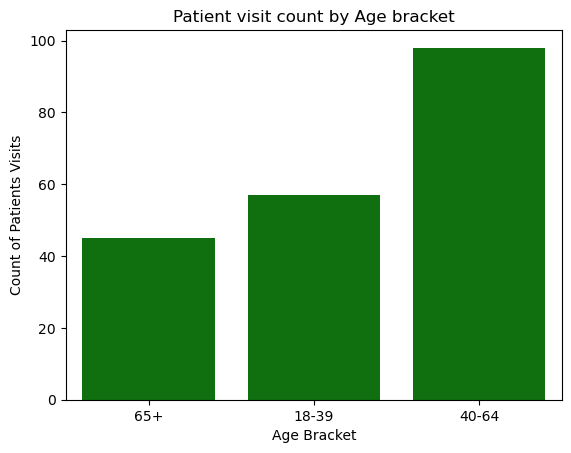

In [19]:
ax=sns.barplot(data=age,x='age_bracket',y='patient_count',color='green')

ax.set(xlabel="Age Bracket", ylabel="Count of Patients Visits", title="Patient visit count by Age bracket")
plt.savefig(r'C:\Users\User\Desktop\Patient Profile & Diagnosis Trends\age_distribution.png')

In [20]:
codes=df.groupby('icd_code')['visit_date'].count().reset_index().sort_values(by='visit_date',ascending=False).iloc[0:10]
codes

,icd_code,visit_date
20,I10,19
47,N39.0,11
33,J45.909,11
9,E11.9,10
42,M54.5,10
12,E78.5,10
13,F32.9,9
23,I25.10,9
34,K21.9,9
17,G43.909,8


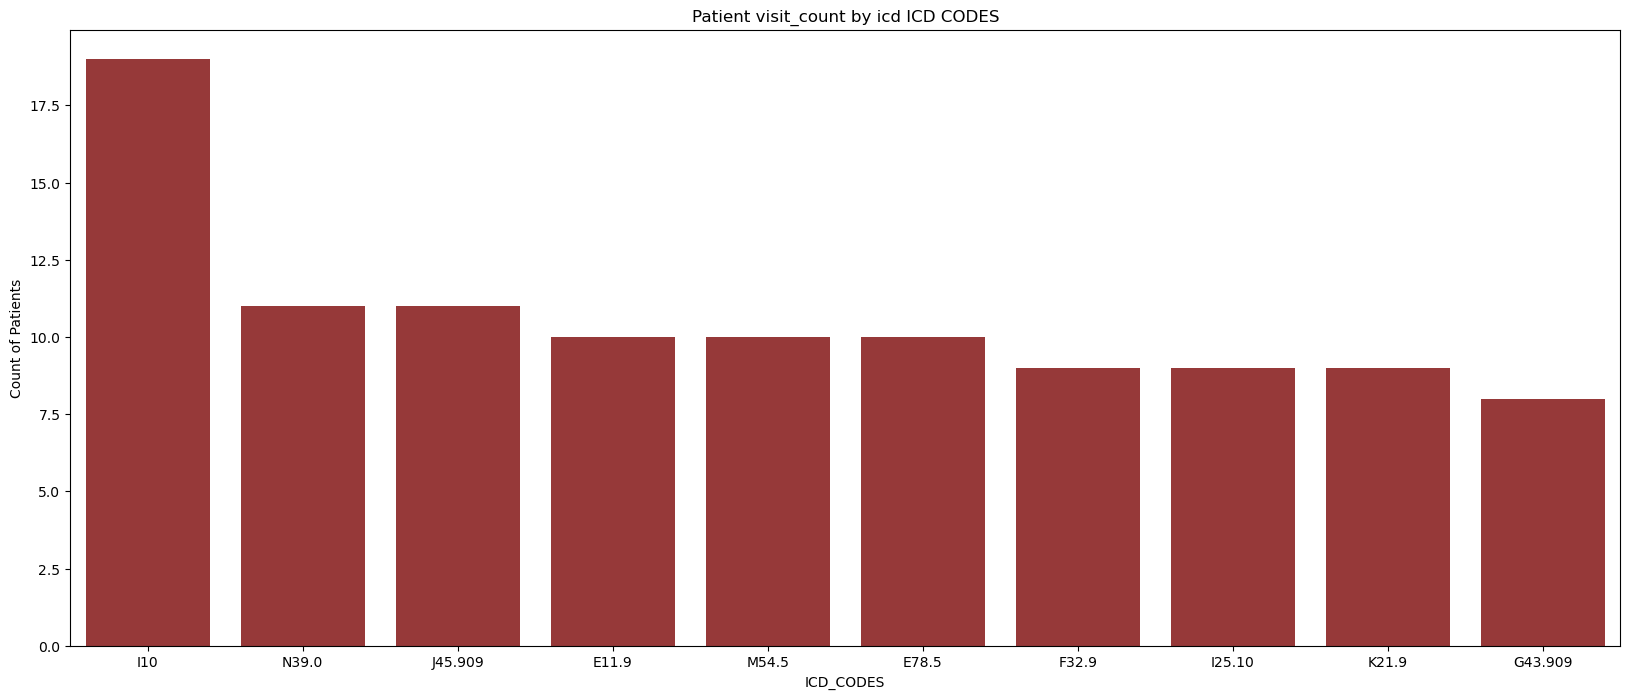

In [21]:
plt.figure(figsize=(20, 8))
ax1=sns.barplot(data=codes,x='icd_code',y='visit_date',color='brown')
ax1.set(xlabel="ICD_CODES", ylabel="Count of Patients", title="Patient visit_count by icd ICD CODES")
plt.savefig(r'C:\Users\User\Desktop\Patient Profile & Diagnosis Trends\icd_codes.png')
plt.show()

In [23]:
visits=df.groupby('patient_id')['visit_date'].count().reset_index()
top=visits[visits['visit_date']>=4]
top['patient_id'].count()

np.int64(20)

In [24]:
visits['visit_date'].mean()

np.float64(4.761904761904762)

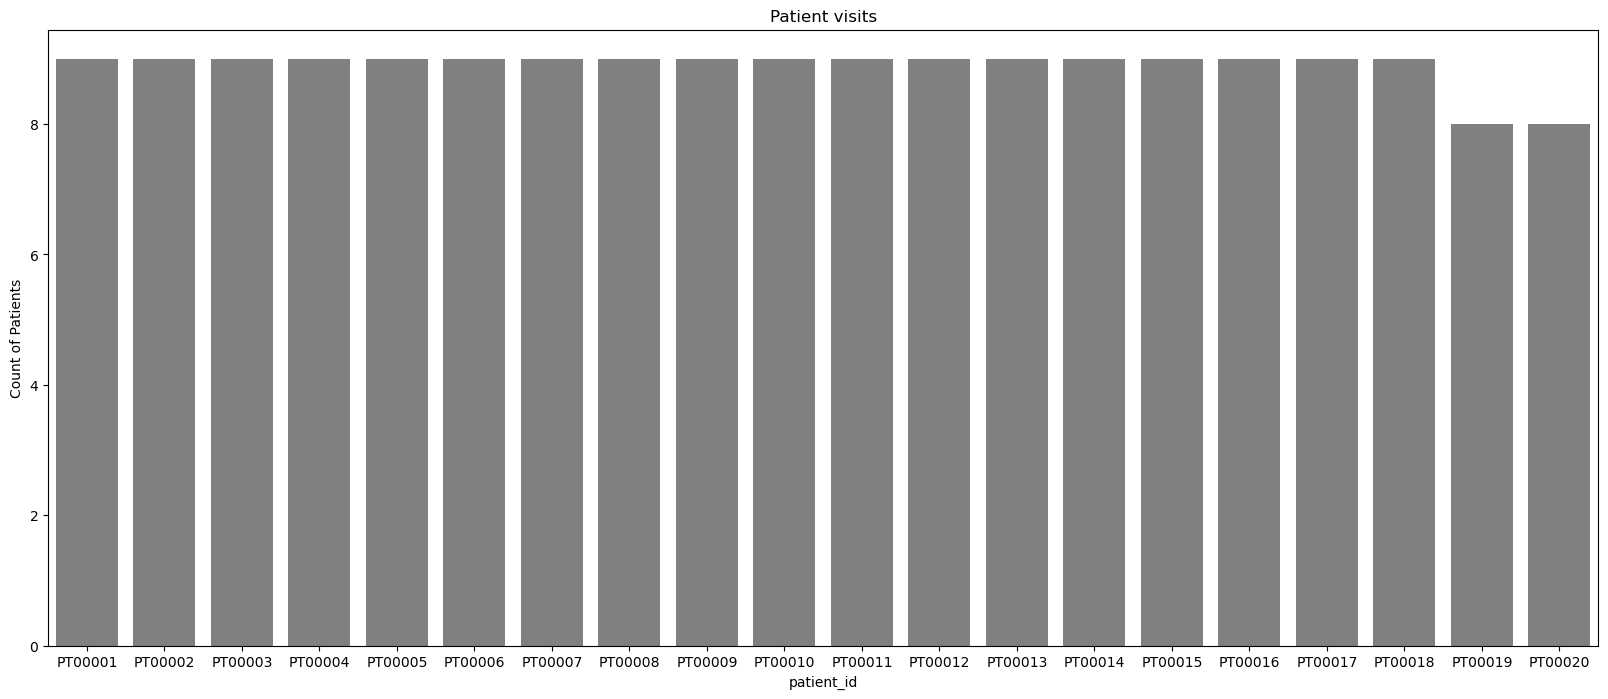

In [25]:
plt.figure(figsize=(20, 8))
ax2=sns.barplot(data=top,x='patient_id',y='visit_date',color='gray')
ax2.set(xlabel="patient_id", ylabel="Count of Patients", title="Patient visits")
plt.savefig(r'C:\Users\User\Desktop\Patient Profile & Diagnosis Trends\high_utilizers.png')
plt.show()

In [26]:
male=df[df['patient_sex']=='Male'].groupby('icd_code')['patient_id'].count().reset_index()
male.rename(columns={'patient_id':'count'},inplace=True)
m1=male.sort_values(by='count',ascending=False)
m1

,icd_code,count
13,I10,8
21,K21.9,6
20,J45.909,6
18,J02.9,6
12,G43.909,5
9,E78.5,5
15,I25.10,4
8,E66.9,4
26,M54.5,4
29,N39.0,3


In [83]:
female=df[df['patient_sex']=='Female'].groupby('icd_code')['patient_id'].count().reset_index()
female.rename(columns={'patient_id':'count'},inplace=True)
f1=female.sort_values(by='count',ascending=False)
f1

,icd_code,count
16,I10,11
5,E11.9,8
37,N39.0,8
33,M54.5,6
9,F32.9,6
10,F41.1,6
27,J45.909,5
42,Z00.00,5
19,I25.10,5
8,E78.5,5


In [98]:
gender=pd.merge(f1,m1,on='icd_code',how='outer',suffixes=('_Male', '_Female'))
gender

,icd_code,count_Male,count_Female
0,A41.9,NaN,1.0
1,C34.90,3.0,NaN
2,C34.91,NaN,1.0
3,C43.9,NaN,1.0
4,C50.911,1.0,1.0
5,C50.912,2.0,1.0
6,D64.9,1.0,NaN
7,E03.9,NaN,2.0
8,E11.65,2.0,1.0
9,E11.9,8.0,2.0


In [101]:
df.groupby(['icd_code','age_bracket'])['patient_id'].count().unstack()

age_bracket,18-39,40-64,65+
icd_code,,,
A41.9,1.0,NaN,NaN
C34.90,1.0,2.0,NaN
C34.91,NaN,NaN,1.0
C43.9,NaN,1.0,NaN
C50.911,NaN,1.0,1.0
C50.912,NaN,3.0,NaN
D64.9,NaN,NaN,1.0
E03.9,NaN,1.0,1.0
E11.65,2.0,1.0,NaN


In [27]:
df.to_csv(r'C:\Users\User\Desktop\Patient Profile & Diagnosis Trends\patient_analysis.csv')